In [1]:
import torch
import glob
import cv2
import matplotlib.pyplot as plt
import random
import os

from super_gradients.training import models
from tqdm.auto import tqdm

/home/sovit/miniconda3/envs/ml/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[2023-05-11 19:12:58] INFO - crash_tips_setup.py - Crash tips is enabled. You can set your environment variable to CRASH_HANDLER=FALSE to disable it


The console stream is logged into /home/sovit/sg_logs/console.log


[2023-05-11 19:12:59] WARNING - __init__.py - Failed to import pytorch_quantization
[2023-05-11 19:12:59] WARNING - calibrator.py - Failed to import pytorch_quantization
[2023-05-11 19:12:59] WARNING - export.py - Failed to import pytorch_quantization
[2023-05-11 19:12:59] WARNING - selective_quantization_utils.py - Failed to import pytorch_quantization


In [2]:
os.makedirs('inference_results/images/', exist_ok=True)

In [3]:
device = torch.device("cuda:0") if torch.cuda.is_available() else torch.device("cpu")

In [4]:
model = models.get(
    model_name='yolo_nas_l',
    checkpoint_path='checkpoints/yolo_nas_l_100e/ckpt_best.pth',
    num_classes=5
).to(device)

[2023-05-11 19:13:03] INFO - checkpoint_utils.py - Successfully loaded model weights from checkpoints/yolo_nas_l_100e/ckpt_best.pth EMA checkpoint.


## Inference on Test Images

In [5]:
ROOT_TEST = 'hit-uav/images/test/'
all_images = os.listdir(ROOT_TEST)

In [6]:
for image in tqdm(all_images, total=len(all_images)):
    image_path = os.path.join(ROOT_TEST, image)
    out = model.predict(image_path)
    out.save('inference_results/images')
    os.rename(
        'inference_results/images/pred_0.jpg', 
        os.path.join('inference_results/images/', image)
    )

100%|█████████████████████████████████████████████████████████████████▉| 570/571 [00:52<00:00, 11.12it/s]

## Overlapped Ground Truth Samples

In [7]:
classes = ['Person', 'Car', 'Bicycle', 'OtherVechicle', 'DontCare']

In [8]:
# Function to convert bounding boxes in YOLO format to xmin, ymin, xmax, ymax.
def yolo2bbox(bboxes):
    xmin, ymin = bboxes[0]-bboxes[2]/2, bboxes[1]-bboxes[3]/2
    xmax, ymax = bboxes[0]+bboxes[2]/2, bboxes[1]+bboxes[3]/2
    return xmin, ymin, xmax, ymax

In [9]:
def plot_box(image, bboxes, labels):
    # Need the image height and width to denormalize
    # the bounding box coordinates
    height, width, _ = image.shape
    lw = max(round(sum(image.shape) / 2 * 0.003), 2)  # Line width.
    tf = max(lw - 1, 1) # Font thickness.
    for box_num, box in enumerate(bboxes):
        x1, y1, x2, y2 = yolo2bbox(box)
        # denormalize the coordinates
        xmin = int(x1*width)
        ymin = int(y1*height)
        xmax = int(x2*width)
        ymax = int(y2*height)

        p1, p2 = (int(xmin), int(ymin)), (int(xmax), int(ymax))
        
        class_name = classes[int(labels[box_num])]

        color = (0, 0, 255)
        
        cv2.rectangle(
            image, 
            p1, p2,
            color=color, 
            thickness=lw,
            lineType=cv2.LINE_AA
        ) 

        # For filled rectangle.
        w, h = cv2.getTextSize(
            class_name, 
            0, 
            fontScale=lw / 3, 
            thickness=tf
        )[0]

        outside = p1[1] - h >= 3
        new_p2 = p1[0] + w, p2[1] + h + 3 if outside else p2[1] - h - 3

        cv2.rectangle(
            image, 
            (p1[0], p2[1]), new_p2, 
            color=color, 
            thickness=-1, 
            lineType=cv2.LINE_AA
        )  
        cv2.putText(
            image, 
            class_name, 
            (p1[0], p2[1] + h + 2 if outside else p2[1]),
            cv2.FONT_HERSHEY_SIMPLEX, 
            fontScale=lw/3, 
            color=(255, 255, 255), 
            thickness=tf, 
            lineType=cv2.LINE_AA
        )
    return image

In [10]:
# Function to plot images with the bounding boxes.
def plot(image_path, label_path, num_samples):
    all_training_images = glob.glob(image_path+'/*')
    all_training_labels = glob.glob(label_path+'/*')
    all_training_images.sort()
    all_training_labels.sort()
    
    temp = list(zip(all_training_images, all_training_labels))
    random.shuffle(temp)
    all_training_images, all_training_labels = zip(*temp)
    all_training_images, all_training_labels = list(all_training_images), list(all_training_labels)
    
    num_images = len(all_training_images)
    
    if num_samples == -1:
        num_samples = num_images
        
    for i in range(num_samples):
        image_name = all_training_images[i].split(os.path.sep)[-1]
        image = cv2.imread(all_training_images[i])
        with open(all_training_labels[i], 'r') as f:
            bboxes = []
            labels = []
            label_lines = f.readlines()
            for label_line in label_lines:
                label, x_c, y_c, w, h = label_line.split(' ')
                x_c = float(x_c)
                y_c = float(y_c)
                w = float(w)
                h = float(h)
                bboxes.append([x_c, y_c, w, h])
                labels.append(label)
        result_image = plot_box(image, bboxes, labels)
        plt.figure(figsize=(12, 9))
        plt.imshow(image[:, :, ::-1])
        plt.axis('off')
        plt.show()

100%|██████████████████████████████████████████████████████████████████| 571/571 [00:52<00:00, 10.88it/s]


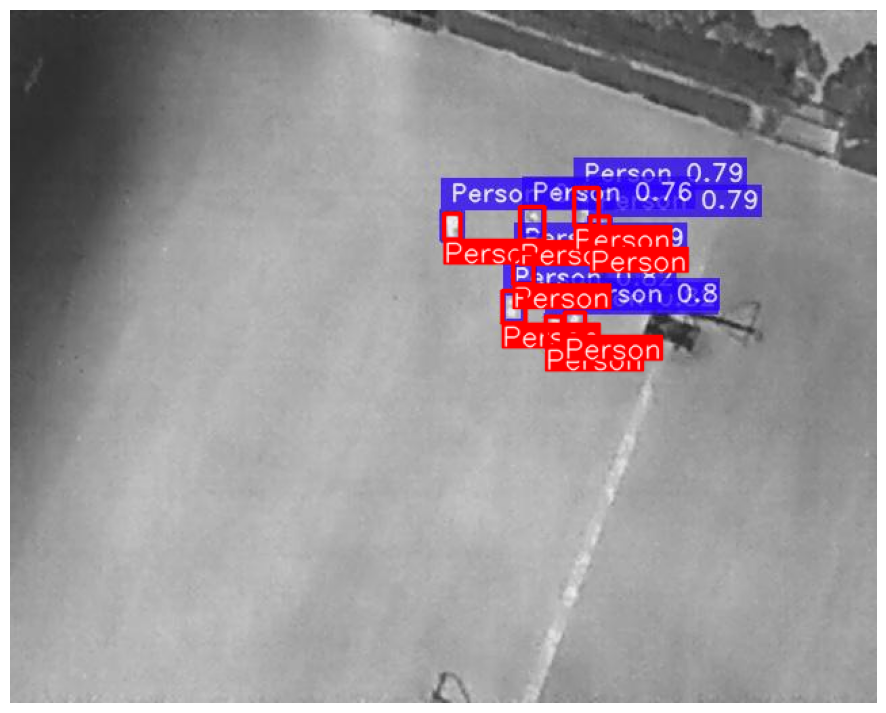

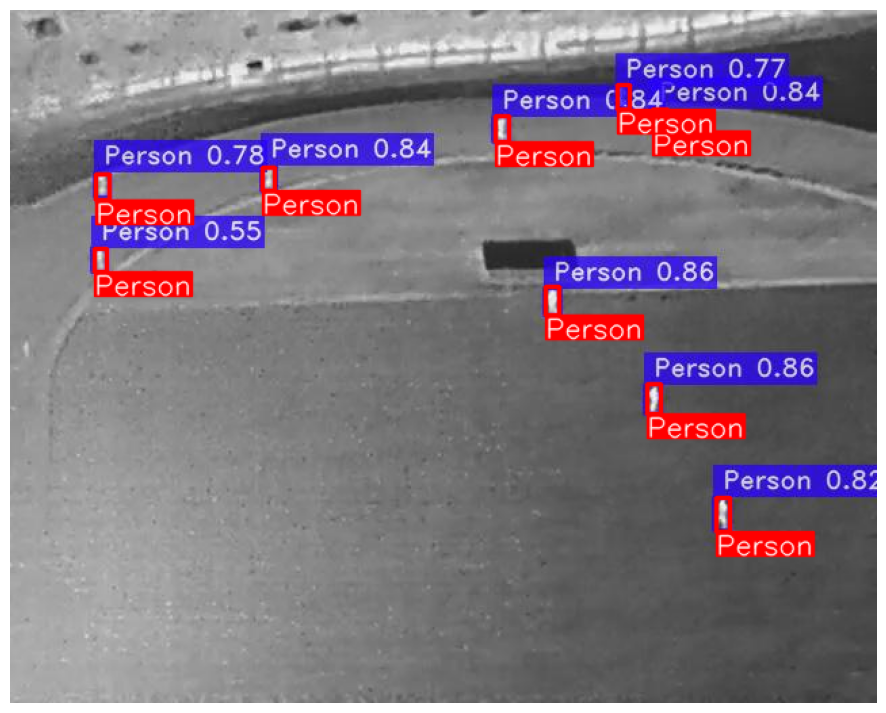

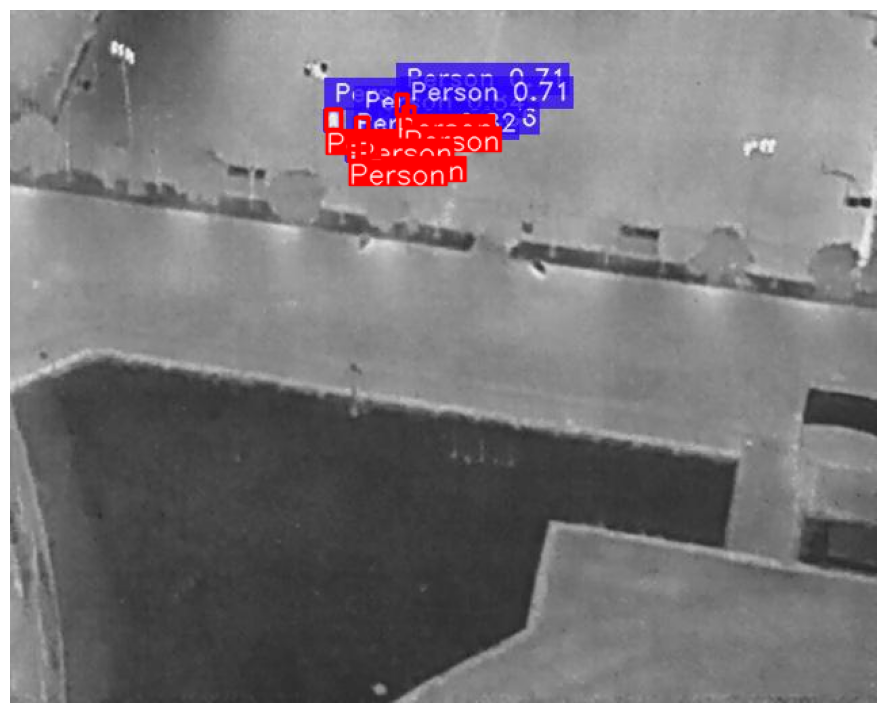

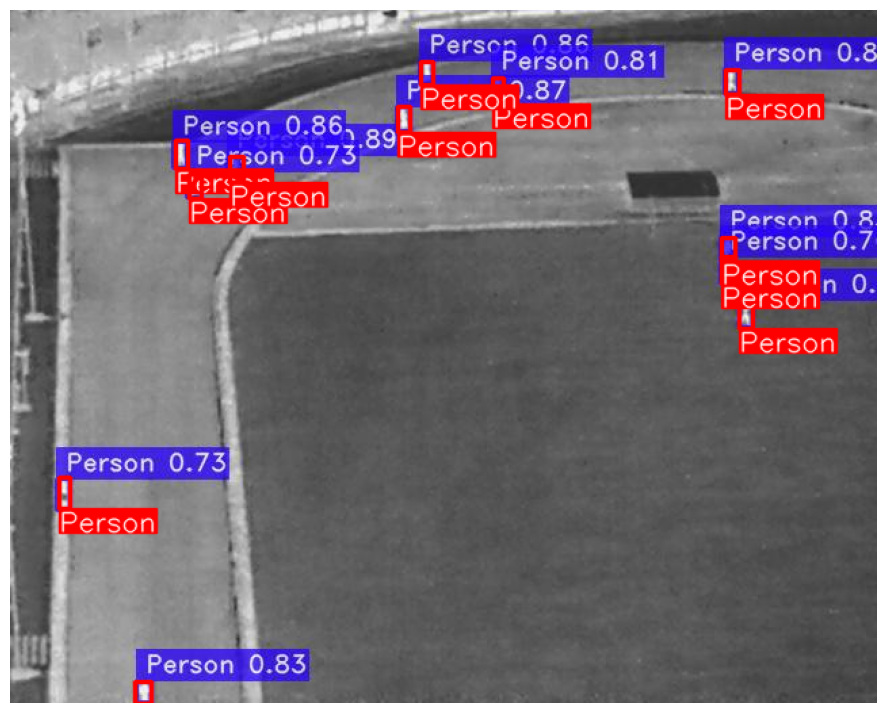

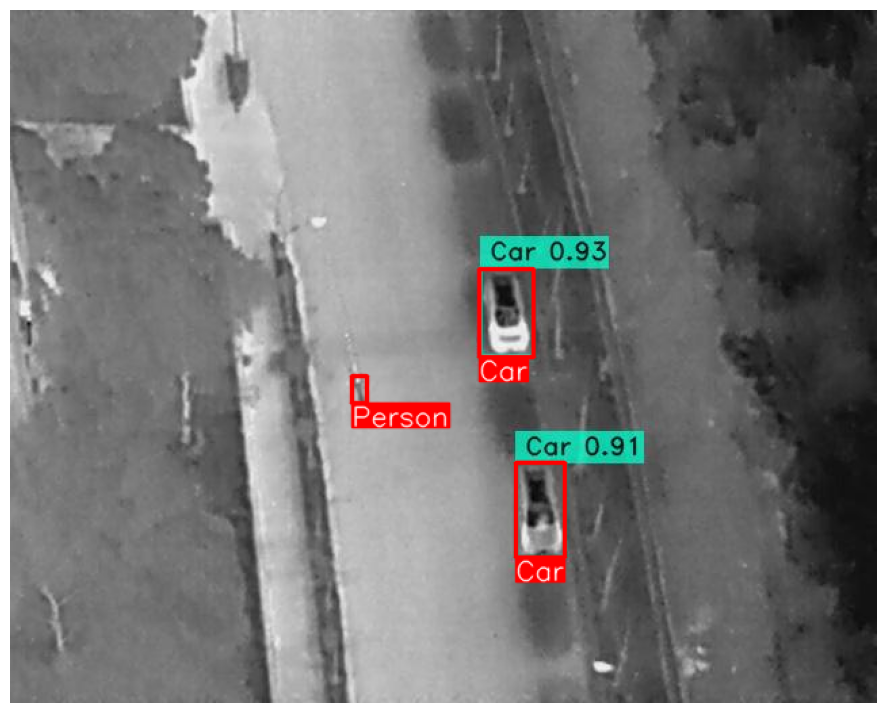

...

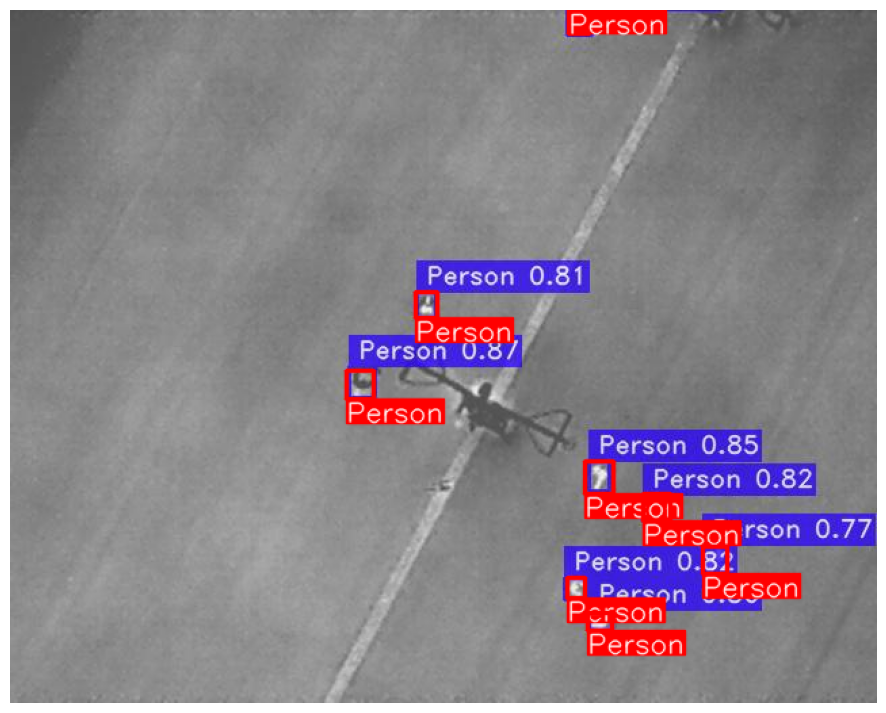

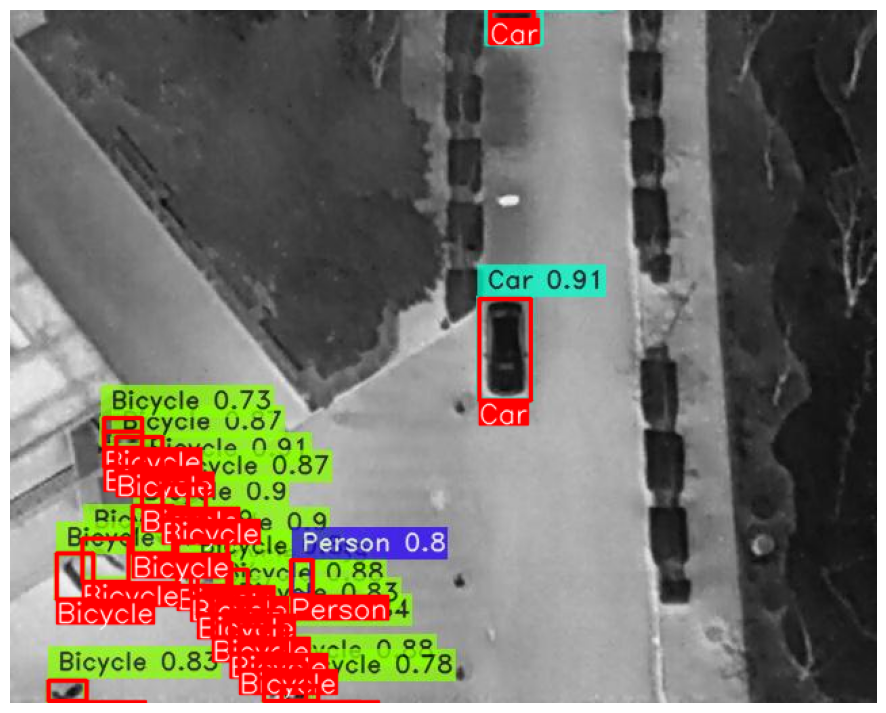

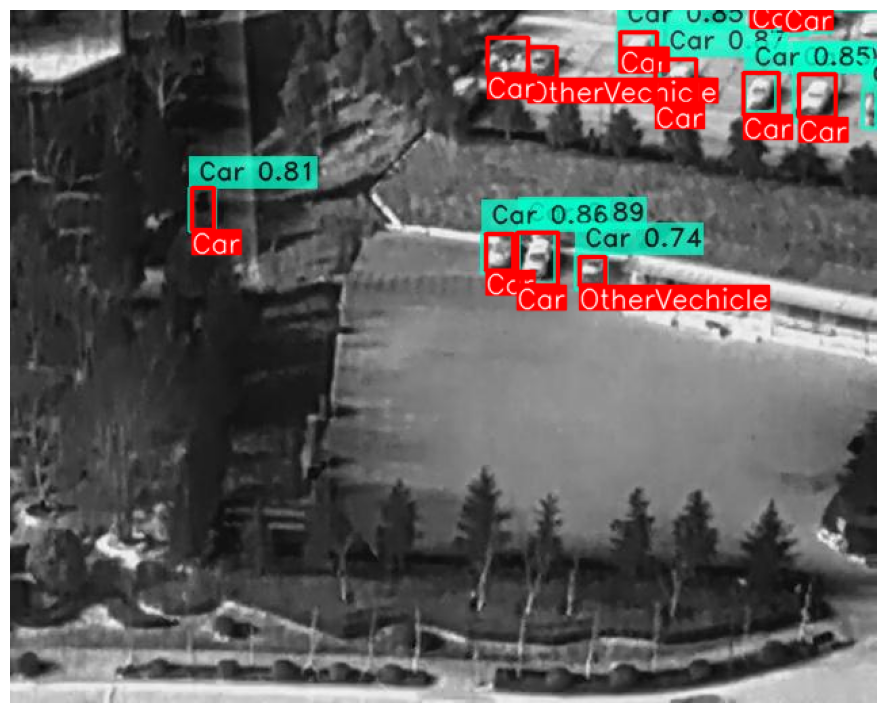

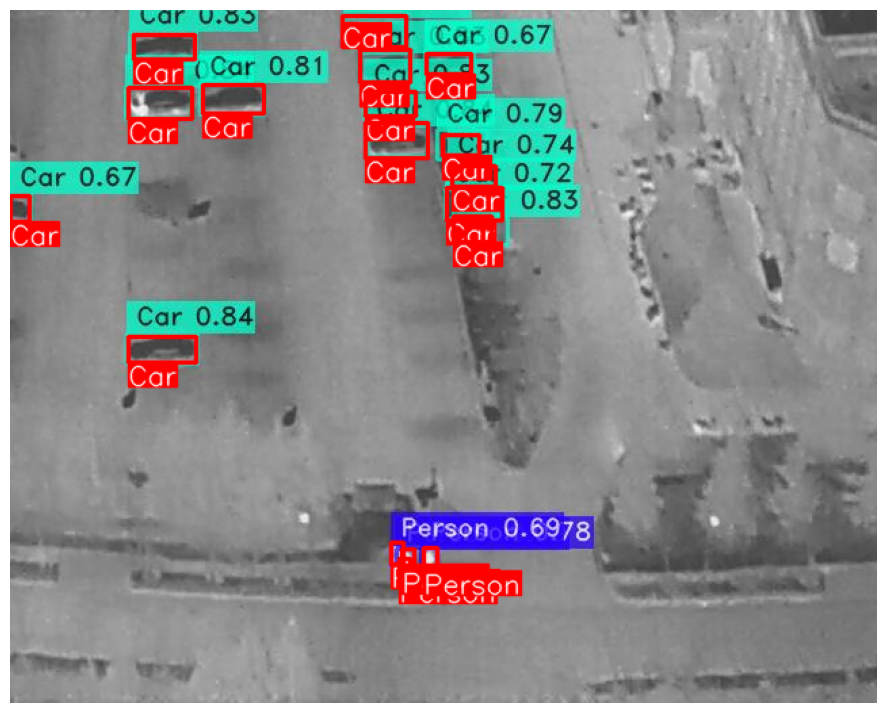

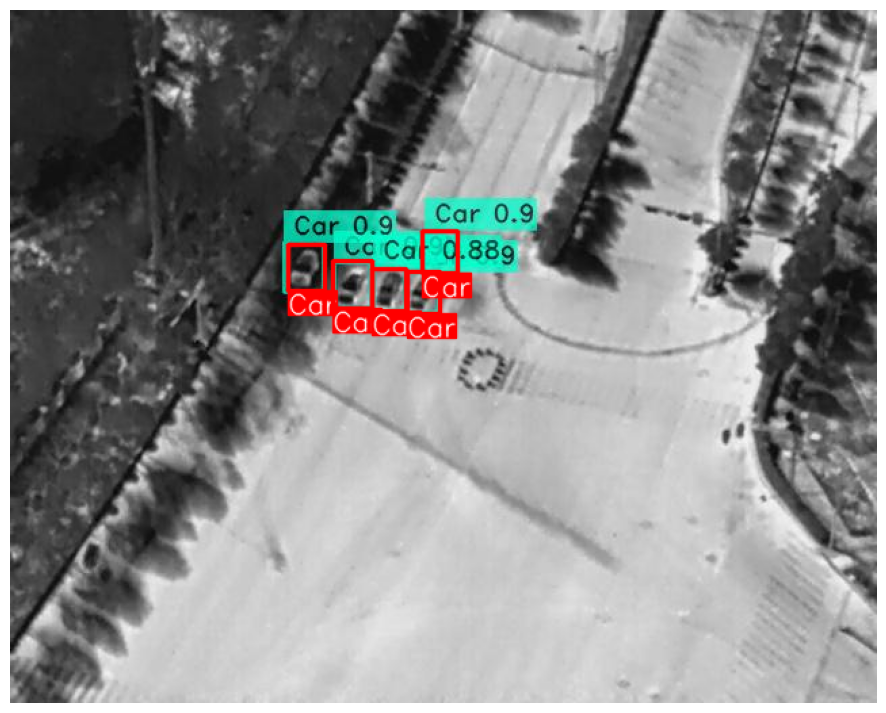

In [11]:
# Visualize a few training images.
plot(
    image_path='inference_results/images/', 
    label_path='hit-uav/labels/test/',
    num_samples=100,
)